# Chest X-Ray Pneumonia Classification — Phase 1
## Classical Machine Learning: EDA, feature engineering, scaling and validation

**Question:** How well can reproducible texture and intensity features discriminate the dataset's NORMAL and PNEUMONIA labels?

This is a student ML benchmark, not a clinical diagnostic system. No neural networks are trained. Positive class: **PNEUMONIA = 1**.

The structure adapts the EDA → features → model evaluation organization of [Inventory-demand-forecasting](https://github.com/tejuuu-7774/Inventory-demand-forecasting). Forecasting methods and metrics are replaced with classification methods suited to radiographs.

**Run in Colab:** choose CPU; upload this notebook using File → Upload notebook. Put the extracted dataset at `/content/chest_xray`, or in Google Drive at `MyDrive/chest_xray`. Run all cells. A Mac Downloads folder is not directly accessible from Colab. Set `DATA_ROOT` below if your folder differs. This notebook embeds the implementation and does not require a GitHub clone.

**Evaluation coverage:** literature review; dataset quality and EDA; justified feature engineering; theoretical rigor; reproducible model comparison; saved artifacts and code quality.

## 1. Literature review and research gap

1. [Kermany et al., Cell (2018)](https://doi.org/10.1016/j.cell.2018.02.010): introduces image-based diagnostic experiments including pediatric pneumonia. Establishes provenance and a deep-learning reference; it does not validate this classical ML implementation. The downloaded dataset is a pediatric, single-source benchmark, so generalization to adult or external-hospital images is unproven.
2. [Dalal & Triggs, CVPR (2005)](https://doi.org/10.1109/CVPR.2005.177): motivates gradient orientation histograms. Here HOG is a hand-crafted descriptor of edges, not a learned disease representation. Our explicitly documented implementation omits spatial vote interpolation.
3. [Ojala et al., IEEE TPAMI (2002)](https://doi.org/10.1109/TPAMI.2002.1017623): motivates local binary patterns for texture. We use the 8 immediate square neighbors, a documented variation from circular interpolated sampling.
4. [Cortes & Vapnik, Machine Learning (1995)](https://doi.org/10.1007/BF00994018): motivates margin-based SVM classification; linear SVM is appropriate for high-dimensional texture vectors.
5. [Zech et al., PLOS Medicine (2018)](https://doi.org/10.1371/journal.pmed.1002683): demonstrates hospital-specific confounding and degraded external performance in radiology models. Motivates leakage controls and cautious interpretation.

**Gap and hypothesis:** test whether low-cost, transparent texture descriptors improve over intensity alone and the majority baseline. Literature scores are not directly comparable unless patients, preprocessing, and partitions match. The feature/scaling ablation tests this hypothesis on development folds only.

[Dataset source](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia/data). Inspect the source's current license before redistribution; raw images are excluded from this repository.

In [1]:
import sys, subprocess, importlib.util
from pathlib import Path
IN_COLAB = importlib.util.find_spec('google.colab') is not None
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'numpy>=2,<3', 'pandas>=2.2,<4', 'Pillow>=10,<13',
        'scikit-learn>=1.6,<1.10', 'matplotlib>=3.9,<4', 'joblib>=1.4,<2'])
print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python', sys.version)


Runtime: Local Python 3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


In [2]:
# Edit only this cell to change input/output paths.
DATA_ROOT = Path('/content/chest_xray') if IN_COLAB else Path.home() / 'Downloads/chest_xray'
OUTPUT = Path('/content/pneumonia_phase1') if IN_COLAB else Path.cwd()
if IN_COLAB and not DATA_ROOT.exists():
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = Path('/content/drive/MyDrive/chest_xray')
if not DATA_ROOT.exists():
    raise FileNotFoundError(f'Upload/extract chest_xray or edit DATA_ROOT: {DATA_ROOT}')
for folder in ('Datasets/processed', 'results', 'report/figures', 'models'):
    (OUTPUT / folder).mkdir(parents=True, exist_ok=True)
print('Input:', DATA_ROOT, '\nOutput:', OUTPUT)


Input: /Users/ravichandrashinde/Downloads/chest_xray 
Output: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML


## 2. Implementation and experimental protocol

The following cell contains the same implementation as `src/pipeline.py`, embedded for standalone Colab execution. It defines functions; later cells run the stages separately.

We scan exactly one canonical train/val/test tree, ignore macOS metadata, decode every image, fingerprint grayscale pixels, and form connected groups from filename proxies and duplicate hashes. Development groups touching test are excluded. Label-conflicting exact duplicates are excluded; other exact duplicates are retained once. The small supplied validation set joins development. Three stratified group folds select models and hyperparameters by balanced accuracy. Test labels are never used for tuning; structural overlap auditing necessarily inspects all file identities. All supervised development uses the retained development subset.

Grouping is conservative: IM identifiers are filename proxies, not independently verified patient IDs. Near duplicates and acquisition artifacts can remain. Population representativeness and annotation errors cannot be established from images alone.

In [3]:
"""Phase 1: audit -> EDA -> deterministic features -> grouped ML evaluation.

Run: python -m src.pipeline --data-root ~/Downloads/chest_xray --output .
No images, identifiers, or labels are used as predictor metadata.
"""
from __future__ import annotations

import argparse
import hashlib
import importlib.metadata
import json
import platform
import re
import time
from pathlib import Path

import joblib
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_score, recall_score, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

SEED = 42
CLASSES = {'NORMAL': 0, 'PNEUMONIA': 1}


def save_json(value, path):
    Path(path).write_text(json.dumps(value, indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)))


def resolve_root(root):
    root = Path(root).expanduser().resolve()
    candidates = [root, root / 'chest_xray', root / 'chest_xray' / 'chest_xray']
    for candidate in candidates:
        if all((candidate / s / c).is_dir() for s in ('train', 'val', 'test') for c in CLASSES):
            return candidate
    raise FileNotFoundError(f'Expected train/val/test with NORMAL/PNEUMONIA beneath {root}')


def patient_proxy(name):
    """Filename-derived proxy, NOT a verified patient identifier."""
    stem = Path(name).stem
    m = re.match(r'(person\d+)_', stem)
    if m:
        return m.group(1)
    m = re.match(r'((?:NORMAL2-)?IM-\d+)', stem)
    return m.group(1) if m else 'unknown:' + stem


def audit(root, out):
    root = resolve_root(root)
    records, corrupt = [], []
    for split in ('train', 'val', 'test'):
        for label, target in CLASSES.items():
            for path in sorted((root / split / label).iterdir()):
                if path.suffix.lower() not in {'.jpeg', '.jpg', '.png'} or path.name.startswith('._'):
                    continue
                try:
                    with Image.open(path) as im:
                        im.load()
                        gray = im.convert('L')
                        arr = np.asarray(gray)
                        # Dimensions are part of the pixel fingerprint; compression bytes are not.
                        digest = hashlib.sha256(str(arr.shape).encode() + arr.tobytes()).hexdigest()
                        records.append(dict(path=str(path.relative_to(root)), split=split, label=label,
                            target=target, width=im.width, height=im.height, mode=im.mode,
                            mean_intensity=float(arr.mean()), std_intensity=float(arr.std()),
                            dark_fraction=float((arr <= 5).mean()), bright_fraction=float((arr >= 250).mean()),
                            pixel_hash=digest, patient_proxy=patient_proxy(path.name)))
                except (OSError, ValueError) as exc:
                    corrupt.append({'path': str(path.relative_to(root)), 'error': str(exc)})
    df = pd.DataFrame(records)
    if df.empty:
        raise ValueError('No readable images found')
    # Connected components bind same patient proxies AND identical decoded images.
    parent = list(range(len(df)))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for column in ('patient_proxy', 'pixel_hash'):
        for ids in df.groupby(column).indices.values():
            first = int(ids[0])
            for idx in ids[1:]:
                parent[find(int(idx))] = find(first)
    df['group'] = [f'g{find(i)}' for i in range(len(df))]
    conflict_hashes = set(df.groupby('pixel_hash').target.nunique().loc[lambda x: x > 1].index)
    test_groups = set(df.loc[df.split == 'test', 'group'])
    df['excluded_reason'] = ''
    df.loc[(df.split != 'test') & df.group.isin(test_groups), 'excluded_reason'] = 'group_overlap_with_test'
    df.loc[df.pixel_hash.isin(conflict_hashes), 'excluded_reason'] = 'conflicting_duplicate_label'
    eligible = df.excluded_reason.eq('')
    duplicate = df.loc[eligible].duplicated('pixel_hash', keep='first')
    df.loc[duplicate.index[duplicate], 'excluded_reason'] = 'exact_pixel_duplicate'
    df['partition'] = np.where(df.split == 'test', 'test', 'development')
    df.loc[df.excluded_reason.ne(''), 'partition'] = 'excluded'
    df.to_csv(out / 'Datasets/processed/manifest.csv', index=False)
    pd.DataFrame(corrupt, columns=['path', 'error']).to_csv(out / 'results/corrupt_images.csv', index=False)
    summary = dict(root=str(root), readable_images=len(df), corrupt_images=len(corrupt),
        original_counts=df.groupby(['split','label']).size().to_dict(),
        duplicate_pixel_images=int(df.duplicated('pixel_hash').sum()),
        cross_split_hash_groups=int((df.groupby('pixel_hash').split.nunique() > 1).sum()),
        conflicting_pixel_hashes=len(conflict_hashes),
        exclusions=df.loc[df.partition == 'excluded', 'excluded_reason'].value_counts().to_dict(),
        retained_counts=df.loc[df.partition != 'excluded'].groupby(['partition','label']).size().to_dict(),
        patient_identity_caveat='Filename proxies only; true patient disjointness cannot be certified. Near duplicates are not fully detected.')
    # JSON keys cannot be tuples.
    for key in ('original_counts','retained_counts'):
        summary[key] = {'/'.join(k):v for k,v in summary[key].items()}
    save_json(summary, out / 'results/dataset_audit.json')
    return root, df, summary


def eda(root, df, out):
    figdir = out / 'report/figures'
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    df.groupby(['split','label']).size().unstack().plot.bar(ax=axes[0], color=['#526575','#ac6045'])
    axes[0].set(title='Original split and class counts', xlabel='Supplied split', ylabel='Images')
    for label in CLASSES:
        subset = df[df.label == label]
        axes[1].scatter(subset.width, subset.height, s=4, alpha=.2, label=label)
        axes[2].hist(subset.mean_intensity, bins=30, alpha=.5, label=label)
    axes[1].set(title='Image dimensions before resizing', xlabel='Width (pixels)', ylabel='Height (pixels)')
    axes[2].set(title='Image mean brightness', xlabel='Mean grayscale intensity (0–255)', ylabel='Images')
    axes[1].legend(); axes[2].legend(); fig.tight_layout()
    fig.savefig(figdir / 'eda_overview.png', dpi=160); plt.close(fig)
    # Example selection uses development images only.
    fig, axes = plt.subplots(2, 4, figsize=(12, 7))
    for i, label in enumerate(CLASSES):
        samples = df[(df.label == label) & (df.partition == 'development')].sample(4, random_state=SEED)
        for ax, row in zip(axes[i], samples.itertuples()):
            with Image.open(root / row.path) as im:
                ax.imshow(im.convert('L'), cmap='gray')
            ax.set_title(f'{label}\n{row.width} × {row.height} px'); ax.axis('off')
    fig.suptitle('Seeded development examples; labels are dataset annotations')
    fig.tight_layout(); fig.savefig(figdir / 'example_radiographs.png', dpi=140); plt.close(fig)
    df.groupby(['split','label'])[['width','height','mean_intensity','std_intensity','dark_fraction','bright_fraction']].describe().to_csv(out / 'results/eda_statistics.csv')


def texture_features(x, u8):
    """Explicit NumPy descriptors: unsigned HOG and square-neighborhood LBP.

    HOG: 9 orientation bins, linear orientation votes, 8x8 cells,
    2x2 overlapping blocks, L2-Hys. No spatial interpolation of cell votes.
    LBP: 8 immediate neighbors (diagonals at sqrt(2)), uniform rotation-
    invariant code = number of ones if <=2 transitions, otherwise bin 9.
    This square-neighborhood LBP is not circular interpolated radius-1 LBP.
    """
    gy, gx = np.gradient(x)
    mag = np.hypot(gx, gy)
    angle = (np.degrees(np.arctan2(gy,gx)) % 180) / 20
    lower = np.floor(angle).astype(int) % 9
    fraction = angle - np.floor(angle)
    rr, cc = np.indices(x.shape)
    cells = np.zeros((8,8,9),dtype=np.float32)
    np.add.at(cells,(rr//8,cc//8,lower),mag*(1-fraction))
    np.add.at(cells,(rr//8,cc//8,(lower+1)%9),mag*fraction)
    blocks=[]
    for r in range(7):
        for c in range(7):
            block=cells[r:r+2,c:c+2].ravel().copy()
            block/=np.sqrt(np.dot(block,block)+1e-10)
            block=np.minimum(block,.2)
            block/=np.sqrt(np.dot(block,block)+1e-10)
            blocks.append(block)
    center=u8[1:-1,1:-1]
    offsets=[(-1,-1),(-1,0),(-1,1),(0,1),(1,1),(1,0),(1,-1),(0,-1)]
    bits=np.stack([u8[1+dr:63+dr,1+dc:63+dc]>=center for dr,dc in offsets])
    transitions=np.sum(bits!=np.roll(bits,1,axis=0),axis=0)
    codes=np.where(transitions<=2,bits.sum(axis=0),9)
    lh=np.bincount(codes.ravel(),minlength=10).astype(float)
    return np.concatenate(blocks),lh/lh.sum()


def extract_one(path):
    with Image.open(path) as im:
        # Preserve anatomy proportions; padding is fixed, not learned.
        image = ImageOps.pad(im.convert('L'), (64,64), method=Image.Resampling.BILINEAR, color=0)
        u8 = np.asarray(image)
    x = u8.astype(np.float32) / 255.0
    h, lh = texture_features(x,u8)
    ih = np.histogram(x, bins=16, range=(0,1))[0].astype(float) / x.size
    stats = np.array([x.mean(), x.std(), *np.quantile(x,[.1,.25,.5,.75,.9]),
                      np.mean(np.abs(np.diff(x,axis=0))), np.mean(np.abs(np.diff(x,axis=1)))])
    return np.concatenate([h, lh, ih, stats]).astype(np.float32)


def features(root, df, out):
    selected = df[df.partition != 'excluded'].copy().reset_index(drop=True)
    x = np.stack([extract_one(root / path) for path in selected.path])
    assert np.isfinite(x).all()
    np.savez_compressed(out / 'Datasets/processed/features.npz', X=x, y=selected.target.to_numpy())
    selected.to_csv(out / 'Datasets/processed/retained_manifest.csv', index=False)
    save_json({'size':[64,64], 'features':x.shape[1], 'hog':1764, 'lbp':10, 'intensity_histogram':16,
               'summary_statistics':9,'pixel_normalization':'divide by 255 (fixed)',
               'learned_scaling':'StandardScaler fitted within CV pipeline; never on test'}, out / 'results/features.json')
    return selected, x


def scores(y, score, pred):
    tn, fp, fn, tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y,pred), balanced_accuracy=balanced_accuracy_score(y,pred),
        precision=precision_score(y,pred,zero_division=0), recall=recall_score(y,pred,zero_division=0),
        specificity=tn/(tn+fp), f1=f1_score(y,pred,zero_division=0),
        roc_auc=roc_auc_score(y,score), average_precision=average_precision_score(y,score),
        tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))


def group_bootstrap(y, score, pred, groups, n=1000):
    rng = np.random.default_rng(SEED)
    unique = np.unique(groups)
    ids = {g: np.flatnonzero(groups==g) for g in unique}
    rows = []
    for _ in range(n):
        idx = np.concatenate([ids[g] for g in rng.choice(unique,len(unique),replace=True)])
        if len(np.unique(y[idx])) == 2:
            rows.append(scores(y[idx],score[idx],pred[idx]))
    return {k: {'lower':float(np.quantile([r[k] for r in rows],.025)),
                'upper':float(np.quantile([r[k] for r in rows],.975))}
            for k in ('balanced_accuracy','recall','specificity','f1','roc_auc','average_precision')}


def train(selected, x, out):
    dev = selected.partition.eq('development').to_numpy()
    xd, xt = x[dev], x[~dev]
    yd, yt = selected.target.to_numpy()[dev], selected.target.to_numpy()[~dev]
    gd, gt = selected.group.to_numpy()[dev], selected.group.to_numpy()[~dev]
    assert not set(gd) & set(gt), 'Development/test group leakage'
    cv = list(StratifiedGroupKFold(3,shuffle=True,random_state=SEED).split(xd,yd,gd))
    for tr, va in cv:
        assert not set(gd[tr]) & set(gd[va])
        assert len(np.unique(yd[va])) == 2
    fold_assignment = np.zeros(len(yd),dtype=int)
    for f, (_, va) in enumerate(cv): fold_assignment[va] = f
    selected.loc[dev,['path','target','group']].assign(cv_fold=fold_assignment).to_csv(out / 'results/cv_folds.csv',index=False)
    candidates = {
        'majority_baseline': (DummyClassifier(strategy='most_frequent'), {}),
        'logistic_regression': (Pipeline([('scale',StandardScaler()),('model',LogisticRegression(class_weight='balanced',max_iter=3000,random_state=SEED))]), {'model__C':[.01,.1,1.]}),
        'linear_svm': (Pipeline([('scale',StandardScaler()),('model',LinearSVC(class_weight='balanced',dual='auto',max_iter=10000,random_state=SEED))]), {'model__C':[.001,.01,.1]}),
        'random_forest': (RandomForestClassifier(n_estimators=200,class_weight='balanced',max_features='sqrt',n_jobs=2,random_state=SEED), {'min_samples_leaf':[2,5]}),
    }
    rows, fitted = [], {}
    for name, (estimator, grid) in candidates.items():
        print('Training',name,flush=True)
        start = time.monotonic()
        search = GridSearchCV(estimator,grid,scoring={'balanced_accuracy':'balanced_accuracy','roc_auc':'roc_auc','recall':'recall'},
            refit='balanced_accuracy',cv=cv,n_jobs=1,return_train_score=True,error_score='raise')
        search.fit(xd,yd)
        pd.DataFrame(search.cv_results_).to_csv(out / f'results/cv_{name}.csv',index=False)
        best = search.best_index_
        rows.append(dict(model=name,cv_balanced_accuracy=search.best_score_,
            cv_std=search.cv_results_['std_test_balanced_accuracy'][best],
            cv_roc_auc=search.cv_results_['mean_test_roc_auc'][best],
            train_balanced_accuracy=search.cv_results_['mean_train_balanced_accuracy'][best],
            best_params=json.dumps(search.best_params_),seconds=time.monotonic()-start))
        fitted[name] = search.best_estimator_
    comparison = pd.DataFrame(rows).sort_values('cv_balanced_accuracy',ascending=False)
    comparison.to_csv(out / 'results/model_comparison_cv.csv',index=False)
    # Final selection uses development CV only; test results never rank models.
    winner = comparison.iloc[0].model
    model = fitted[winner]
    method = 'decision_function' if hasattr(model,'decision_function') else 'predict_proba'
    oof = cross_val_predict(clone(model),xd,yd,cv=cv,method=method,n_jobs=1)
    if oof.ndim == 2: oof = oof[:,1]
    default_threshold = 0. if method == 'decision_function' else .5
    precision, recall, thresholds = precision_recall_curve(yd,oof)
    f1 = 2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    threshold = float(thresholds[np.argmax(f1)])
    pd.DataFrame({'target':yd,'score':oof,'group':gd}).to_csv(out / 'results/development_oof_predictions.csv',index=False)
    raw = getattr(model,method)(xt)
    if raw.ndim == 2: raw = raw[:,1]
    pred = (raw>=threshold).astype(int)
    default_pred = model.predict(xt)
    result = dict(selected_model=winner, selection_metric='3-fold grouped CV balanced accuracy',
        development_images=len(yd),test_images=len(yt),score_type=method,
        default_threshold=default_threshold, f1_threshold_from_development_oof=threshold,
        threshold_caveat='OOF threshold is selected after hyperparameter tuning; development estimates are selection-biased, not nested CV. Test untouched until all choices fixed.',
        test_default=scores(yt,raw,default_pred),test_oof_threshold=scores(yt,raw,pred),
        bootstrap_95_ci=group_bootstrap(yt,raw,pred,gt),
        classification_report=classification_report(yt,pred,target_names=list(CLASSES),output_dict=True,zero_division=0))
    save_json(result,out / 'results/final_evaluation.json')
    selected.loc[~dev,['path','target','group']].assign(score=raw,prediction=pred,default_prediction=default_pred).to_csv(out / 'results/test_predictions.csv',index=False)
    joblib.dump({'model':model,'threshold':threshold,'score_method':method,'classes':CLASSES,
                 'image_size':(64,64),'feature_version':1},out / 'models/best_model.joblib')
    fig, axes = plt.subplots(1,3,figsize=(15,4))
    ConfusionMatrixDisplay.from_predictions(yt,pred,display_labels=list(CLASSES),ax=axes[0],colorbar=False)
    axes[0].set_title(f'{winner}: OOF threshold')
    RocCurveDisplay.from_predictions(yt,raw,ax=axes[1]); axes[1].set_title('Held-out test ROC')
    PrecisionRecallDisplay.from_predictions(yt,raw,ax=axes[2]); axes[2].set_title('Held-out test precision–recall')
    axes[2].axhline(yt.mean(),ls='--',color='gray',label='Test prevalence'); axes[2].legend()
    fig.tight_layout(); fig.savefig(out / 'report/figures/final_evaluation.png',dpi=160); plt.close(fig)
    # Feature ablation and scaling control: development folds only.
    ablations=[]
    for name, xx, scale in [('texture_intensity_scaled',xd,True),('texture_intensity_unscaled',xd,False),('intensity_only_scaled',xd[:,-25:],True)]:
        est=Pipeline([('scale',StandardScaler() if scale else 'passthrough'),('model',LogisticRegression(C=.1,class_weight='balanced',max_iter=3000,random_state=SEED))])
        vals=[]
        for tr, va in cv:
            est.fit(xx[tr],yd[tr]); vals.append(balanced_accuracy_score(yd[va],est.predict(xx[va])))
        ablations.append(dict(experiment=name,C=.1,cv_balanced_accuracy=float(np.mean(vals)),cv_std=float(np.std(vals))))
    pd.DataFrame(ablations).to_csv(out / 'results/feature_scaling_ablation.csv',index=False)
    # Illustrate only the training-fitted scaler on first fold.
    tr, va = cv[0]
    scaler=StandardScaler().fit(xd[tr])
    z=scaler.transform(xd[tr]); zv=scaler.transform(xd[va])
    save_json(dict(fold=0,fit_rows=len(tr),validation_rows=len(va),
        max_absolute_training_mean=float(np.abs(z.mean(0)).max()),
        validation_mean_absolute=float(np.abs(zv.mean(0)).mean()),
        constant_features=int((scaler.var_==0).sum())), out / 'results/scaling_diagnostics.json')
    return result


def run(data_root, output='.'):
    out=Path(output).resolve()
    for folder in ('Datasets/processed','results','report/figures','models'):
        (out / folder).mkdir(parents=True,exist_ok=True)
    start=time.monotonic()
    print('Auditing images...',flush=True)
    root,df,summary=audit(data_root,out)
    print(json.dumps(summary,indent=2),flush=True)
    eda(root,df,out)
    print('Extracting HOG, LBP and intensity features...',flush=True)
    selected,x=features(root,df,out)
    result=train(selected,x,out)
    save_json(dict(seed=SEED,python=platform.python_version(),
        packages={p:importlib.metadata.version(p) for p in ['numpy','pandas','Pillow','scikit-learn','matplotlib','joblib']},
        runtime_seconds=time.monotonic()-start),out / 'results/run_environment.json')
    print(json.dumps(result,indent=2),flush=True)
    return result




## 3. Dataset quality audit and EDA

Inspect measured class counts, decode failures, duplicate hashes, exclusions, image sizes and grayscale distributions. EDA is descriptive; it does not establish disease-specific biology. Test appearance summaries are shown for transparency, but preprocessing/model choices are fixed in advance. Report actual local counts rather than repeating a nominal count from a publication.

{
  "root": "/Users/ravichandrashinde/Downloads/chest_xray",
  "readable_images": 5856,
  "corrupt_images": 0,
  "original_counts": {
    "test/NORMAL": 234,
    "test/PNEUMONIA": 390,
    "train/NORMAL": 1341,
    "train/PNEUMONIA": 3875,
    "val/NORMAL": 8,
    "val/PNEUMONIA": 8
  },
  "duplicate_pixel_images": 32,
  "cross_split_hash_groups": 0,
  "conflicting_pixel_hashes": 0,
  "exclusions": {
    "group_overlap_with_test": 457,
    "exact_pixel_duplicate": 28
  },
  "retained_counts": {
    "development/NORMAL": 1348,
    "development/PNEUMONIA": 3405,
    "test/NORMAL": 231,
    "test/PNEUMONIA": 387
  },
  "patient_identity_caveat": "Filename proxies only; true patient disjointness cannot be certified. Near duplicates are not fully detected."
}


images
split label            
test  NORMAL        234
      PNEUMONIA     390
train NORMAL       1341
      PNEUMONIA    3875
val   NORMAL          8
      PNEUMONIA       8

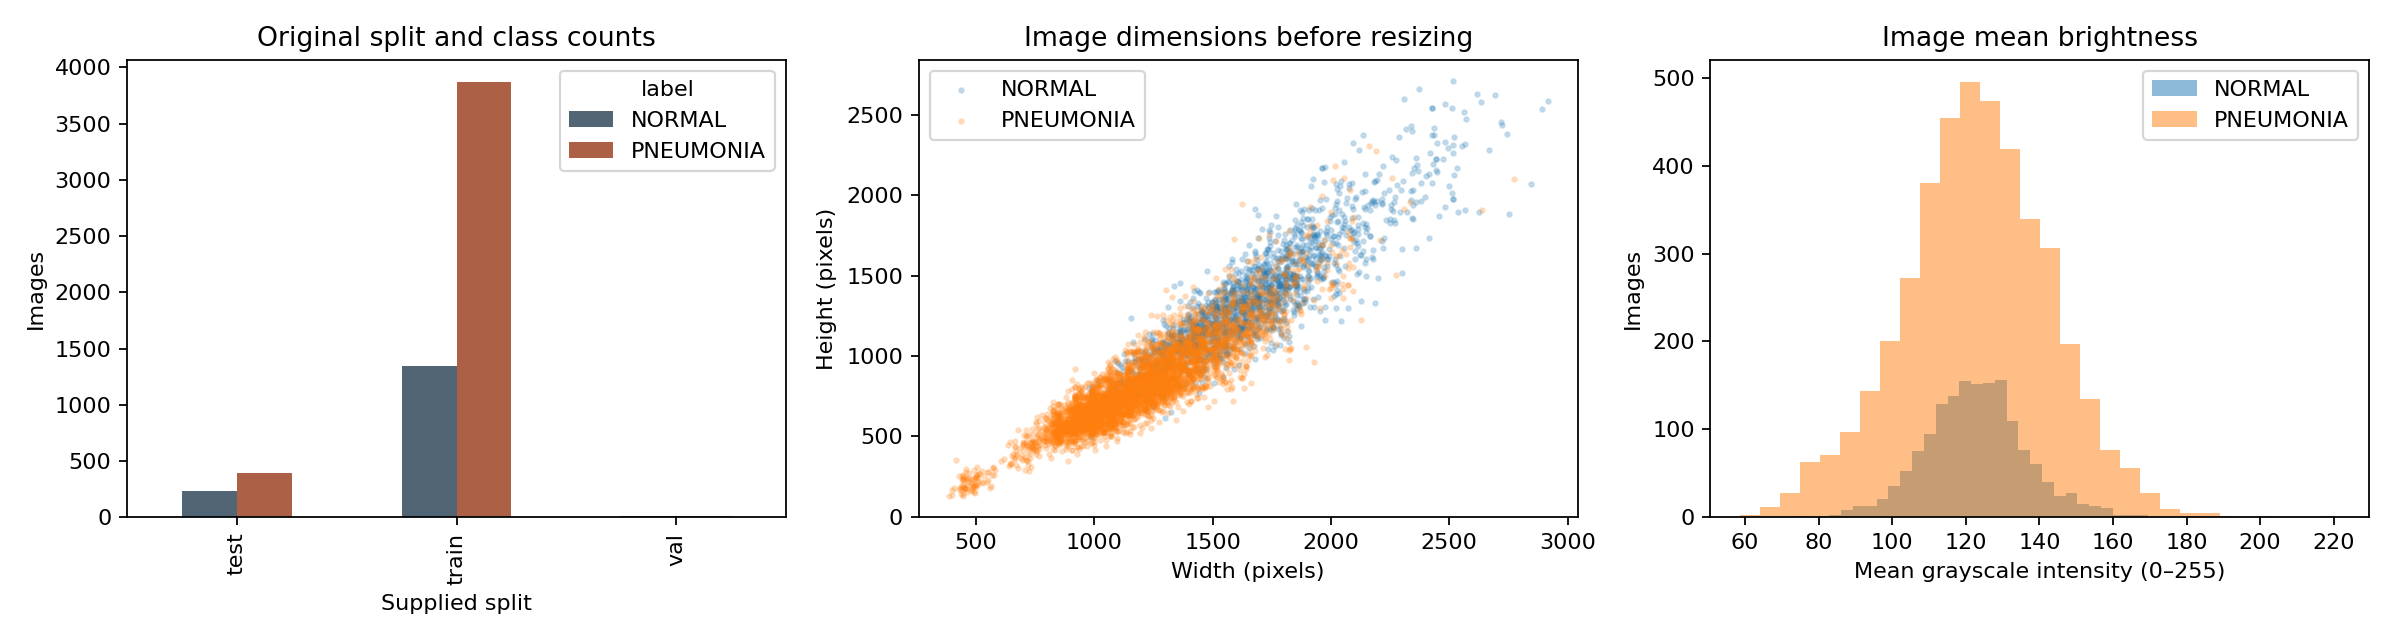

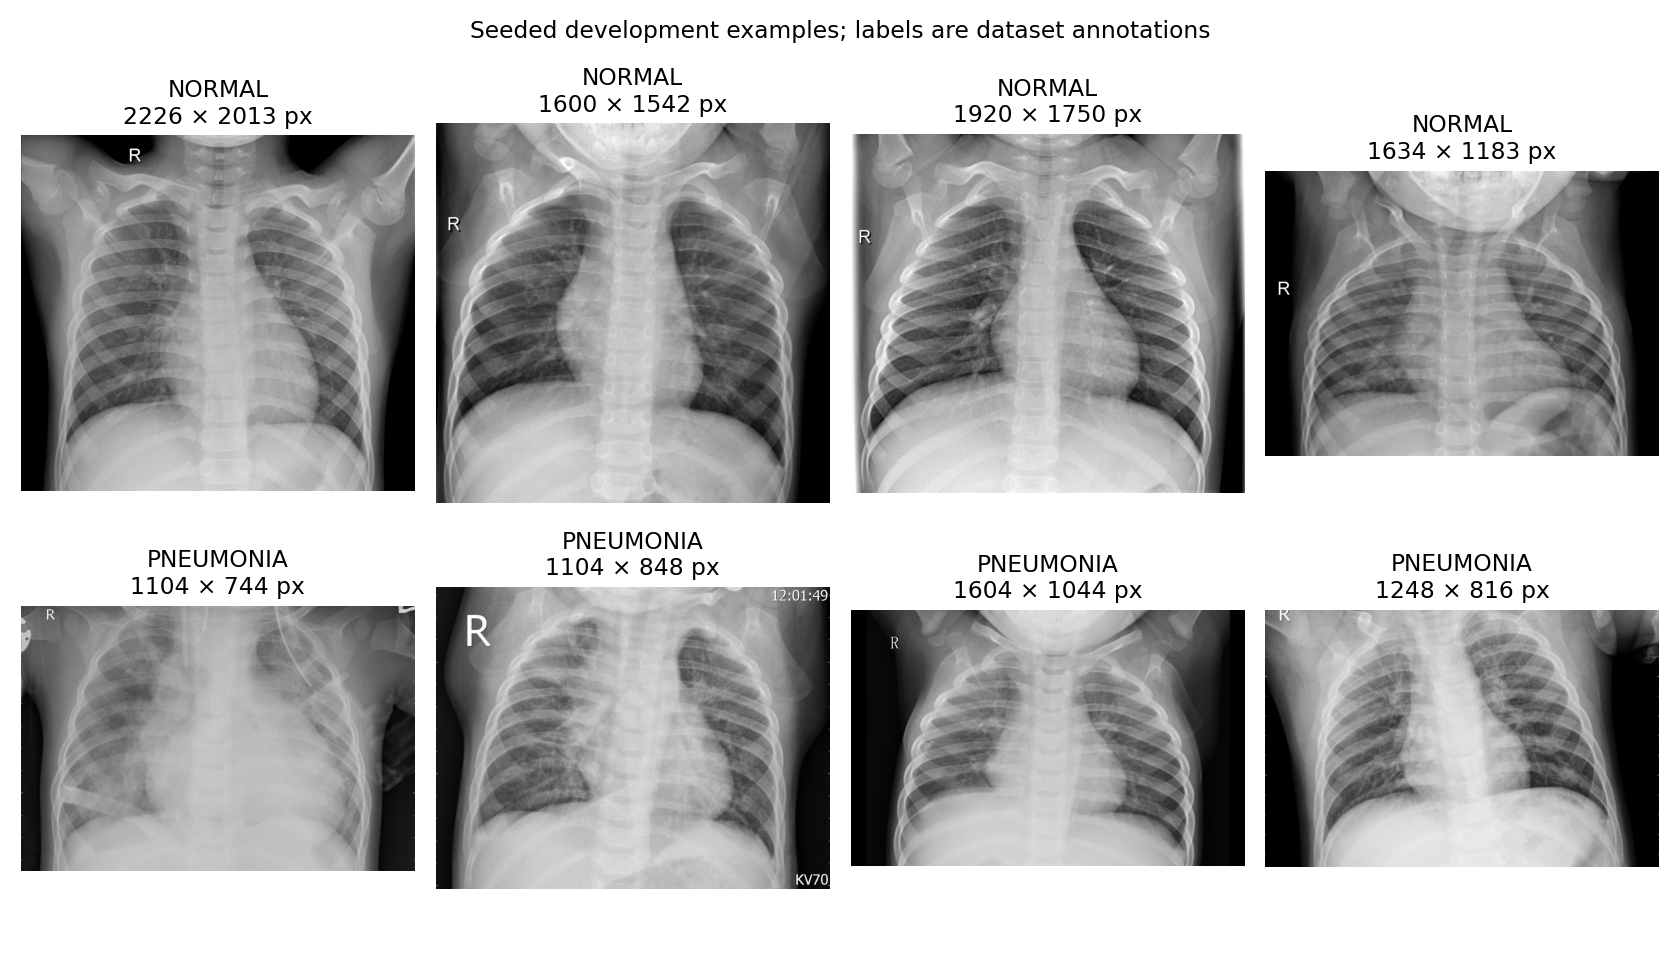

In [4]:
root, manifest, audit_summary = audit(DATA_ROOT, OUTPUT)
print(json.dumps(audit_summary, indent=2))
eda(root, manifest, OUTPUT)
from IPython.display import display, Image as NotebookImage
display(manifest.groupby(['split', 'label']).size().rename('images').to_frame())
display(NotebookImage(filename=str(OUTPUT / 'report/figures/eda_overview.png')))
display(NotebookImage(filename=str(OUTPUT / 'report/figures/example_radiographs.png')))


## 4. Feature engineering and scaling

Grayscale images are aspect-preserving resized and black-padded to 64 × 64. This trades fine detail for CPU speed and avoids shape distortion. Padding and acquisition differences may themselves confound predictions. No lung segmentation or augmentation is applied.

Feature vector: 1,764 HOG + 10 uniform square-neighbor LBP + 16 intensity histogram + 9 summary statistics = **1,799 features**. No filenames, dimensions, split names or patient proxies enter predictors.

Pixel normalization is the fixed transform $x/255$; it learns nothing. Standardization learns $z_j=(x_j-\mu_{j,train})/\sigma_{j,train}$. A `Pipeline` fits the scaler separately inside each CV training fold, then uses that scaler on validation. Final scaling fits development only. Trees use raw feature vectors because monotonic scaling is unnecessary for their splits. HOG block normalization and histogram normalization are local per-image operations, distinct from dataset standardization.

The NumPy descriptor definitions are explicit so this project runs without a specialist image-feature dependency. They are inspired by the cited papers, not exact replicas of their complete implementations.

In [5]:
retained, X = features(root, manifest, OUTPUT)
print('Feature matrix:', X.shape, 'finite:', np.isfinite(X).all())
print((OUTPUT / 'results/features.json').read_text())


Feature matrix: (5371, 1799) finite: True
{
  "size": [
    64,
    64
  ],
  "features": 1799,
  "hog": 1764,
  "lbp": 10,
  "intensity_histogram": 16,
  "summary_statistics": 9,
  "pixel_normalization": "divide by 255 (fixed)",
  "learned_scaling": "StandardScaler fitted within CV pipeline; never on test"
}


## 5. Theory and model application

**Majority baseline:** predicts the majority development label. Accuracy can look high on imbalanced data, while balanced accuracy is 0.5 for a constant classifier with both classes present.

**Logistic regression:** $p(y=1|x)=\sigma(w^Tz+b)$; minimizes class-weighted log loss plus L2 regularization. Smaller `C` increases regularization. It is interpretable as a linear decision function, but correlated image features limit causal interpretation.

**Linear SVM:** minimizes a regularized squared hinge objective, $\frac12\|w\|^2+C\sum_i\alpha_{y_i}\max(0,1-t_i(w^Tz_i+b))^2$. Its decision score is not a calibrated probability. Margin control can limit overfitting in high-dimensional feature spaces.

**Random forest:** averages 200 randomized decision trees; nonlinear reference model with class weighting and leaf-size tuning. Scaling is unnecessary. Tree complexity and correlated artifacts may cause overfitting.

Use class weighting instead of duplicating images or applying SMOTE to image texture vectors. Hyperparameter candidates and folds are fixed with seed 42. Training-vs-CV scores reveal possible overfitting.

Balanced accuracy $=(sensitivity+specificity)/2$ is the selection criterion. Also report precision, recall, specificity, F1, ROC-AUC and average precision. Average precision summarizes a PR curve and is not trapezoidal PR-AUC. AUC uses continuous scores. A development OOF threshold maximizes F1; this is an academic operating point, not a clinical sensitivity requirement. The default operating point is also reported. Hyperparameters are selected before producing OOF predictions, so OOF tuning estimates are not unbiased nested-CV estimates. The final untouched test evaluates the fixed selection.

95% percentile bootstrap intervals resample test groups 1,000 times. They describe sampling variation within this dataset, conditional on the fitted model; they exclude training and deployment uncertainty.

In [6]:
import time, platform, importlib.metadata
started = time.monotonic()
final_result = train(retained, X, OUTPUT)
save_json(dict(seed=SEED, python=platform.python_version(),
    packages={p:importlib.metadata.version(p) for p in ['numpy','pandas','Pillow','scikit-learn','matplotlib','joblib']},
    training_runtime_seconds=time.monotonic()-started), OUTPUT / 'results/run_environment.json')
print(json.dumps(final_result, indent=2))


Training majority_baseline
Training logistic_regression
Training linear_svm
Training random_forest
{
  "selected_model": "logistic_regression",
  "selection_metric": "3-fold grouped CV balanced accuracy",
  "development_images": 4753,
  "test_images": 618,
  "score_type": "decision_function",
  "default_threshold": 0.0,
  "f1_threshold_from_development_oof": -0.27093224748002775,
  "threshold_caveat": "OOF threshold is selected after hyperparameter tuning; development estimates are selection-biased, not nested CV. Test untouched until all choices fixed.",
  "test_default": {
    "accuracy": 0.8268608414239482,
    "balanced_accuracy": 0.7736333434007853,
    "precision": 0.7904564315352697,
    "recall": 0.9844961240310077,
    "specificity": 0.5627705627705628,
    "f1": 0.8768699654775605,
    "roc_auc": 0.9628063581551953,
    "average_precision": 0.9770833490371873,
    "tn": 130,
    "fp": 101,
    "fn": 6,
    "tp": 381
  },
  "test_oof_threshold": {
    "accuracy": 0.82038834951

## 6. Comparison, ablation and error analysis

Model ranking below uses development CV only. The test result is reported only for the selected model, preventing a second selection on test scores. The three ablations hold logistic-regression `C=0.1` fixed to isolate scaling/feature differences; they are not separately tuned competitors. Inspect false positives and false negatives without changing the final model after seeing them.

Scaling check: {
  "fold": 0,
  "fit_rows": 3168,
  "validation_rows": 1585,
  "max_absolute_training_mean": 6.659398422925733e-06,
  "validation_mean_absolute": 0.03362681344151497,
  "constant_features": 0
}
Test errors: 111


,model,cv_balanced_accuracy,cv_std,cv_roc_auc,train_balanced_accuracy,best_params,seconds
0,logistic_regression,0.967973,0.003524,0.994830,0.993894,"{""model__C"": 0.01}",2.796661
1,linear_svm,0.963630,0.002903,0.992657,0.988794,"{""model__C"": 0.001}",10.772729
2,random_forest,0.933707,0.007643,0.985756,0.992040,"{""min_samples_leaf"": 5}",35.509433
3,majority_baseline,0.500000,0.000000,0.500000,0.500000,{},0.032672


,experiment,C,cv_balanced_accuracy,cv_std
0,texture_intensity_scaled,0.1,0.966543,0.004162
1,texture_intensity_unscaled,0.1,0.956865,0.007885
2,intensity_only_scaled,0.1,0.886398,0.003112


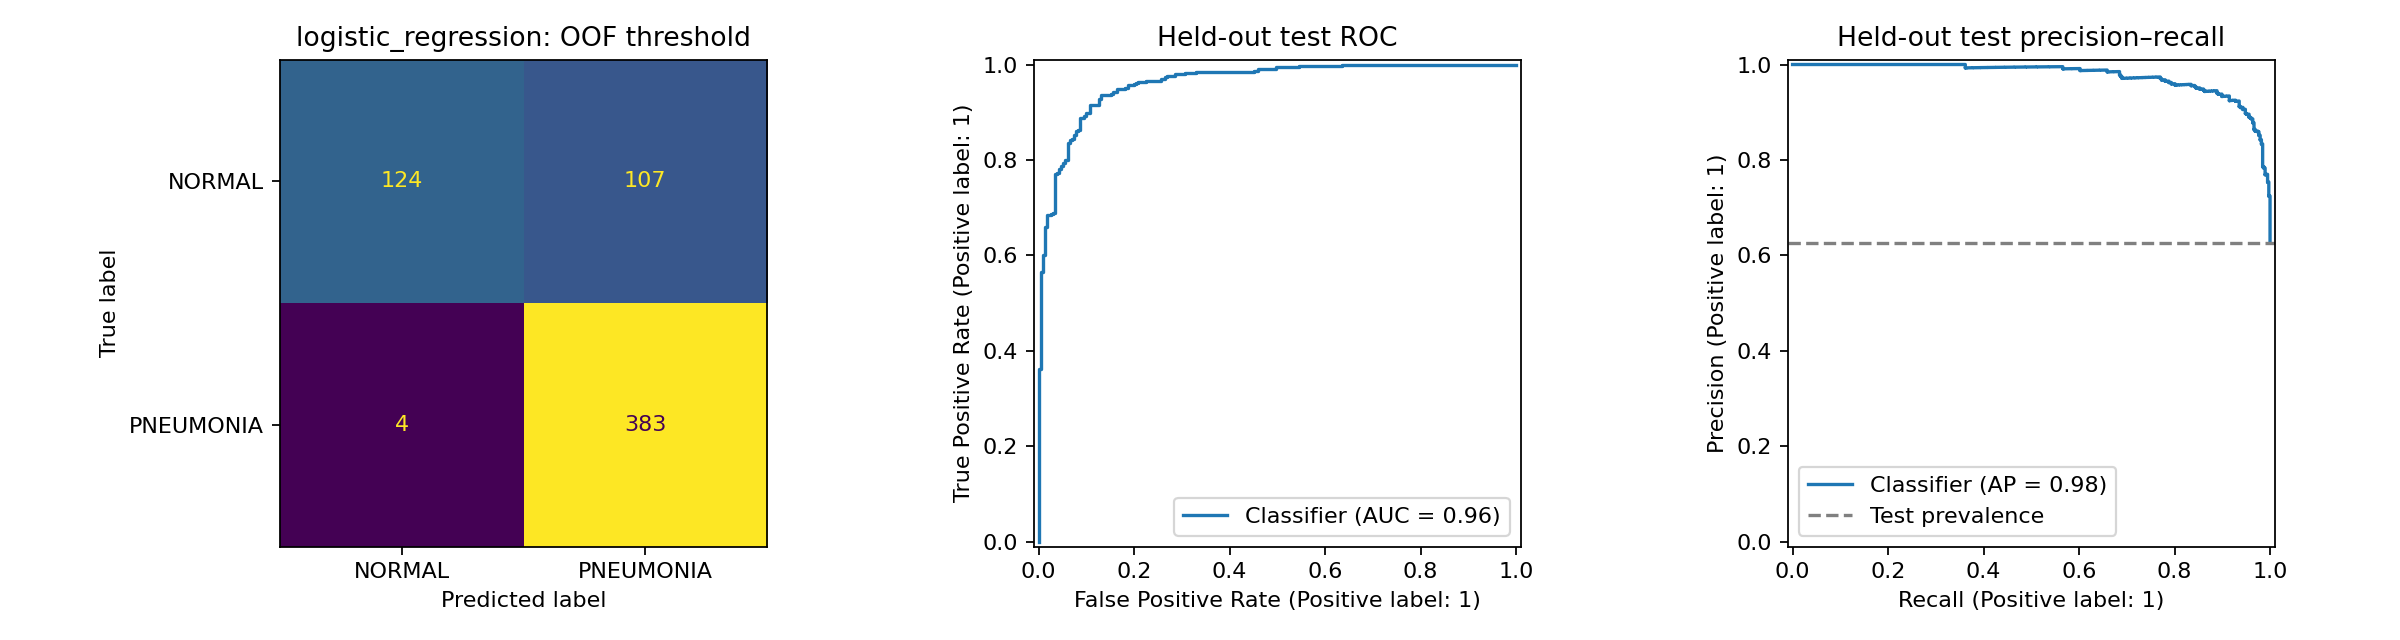

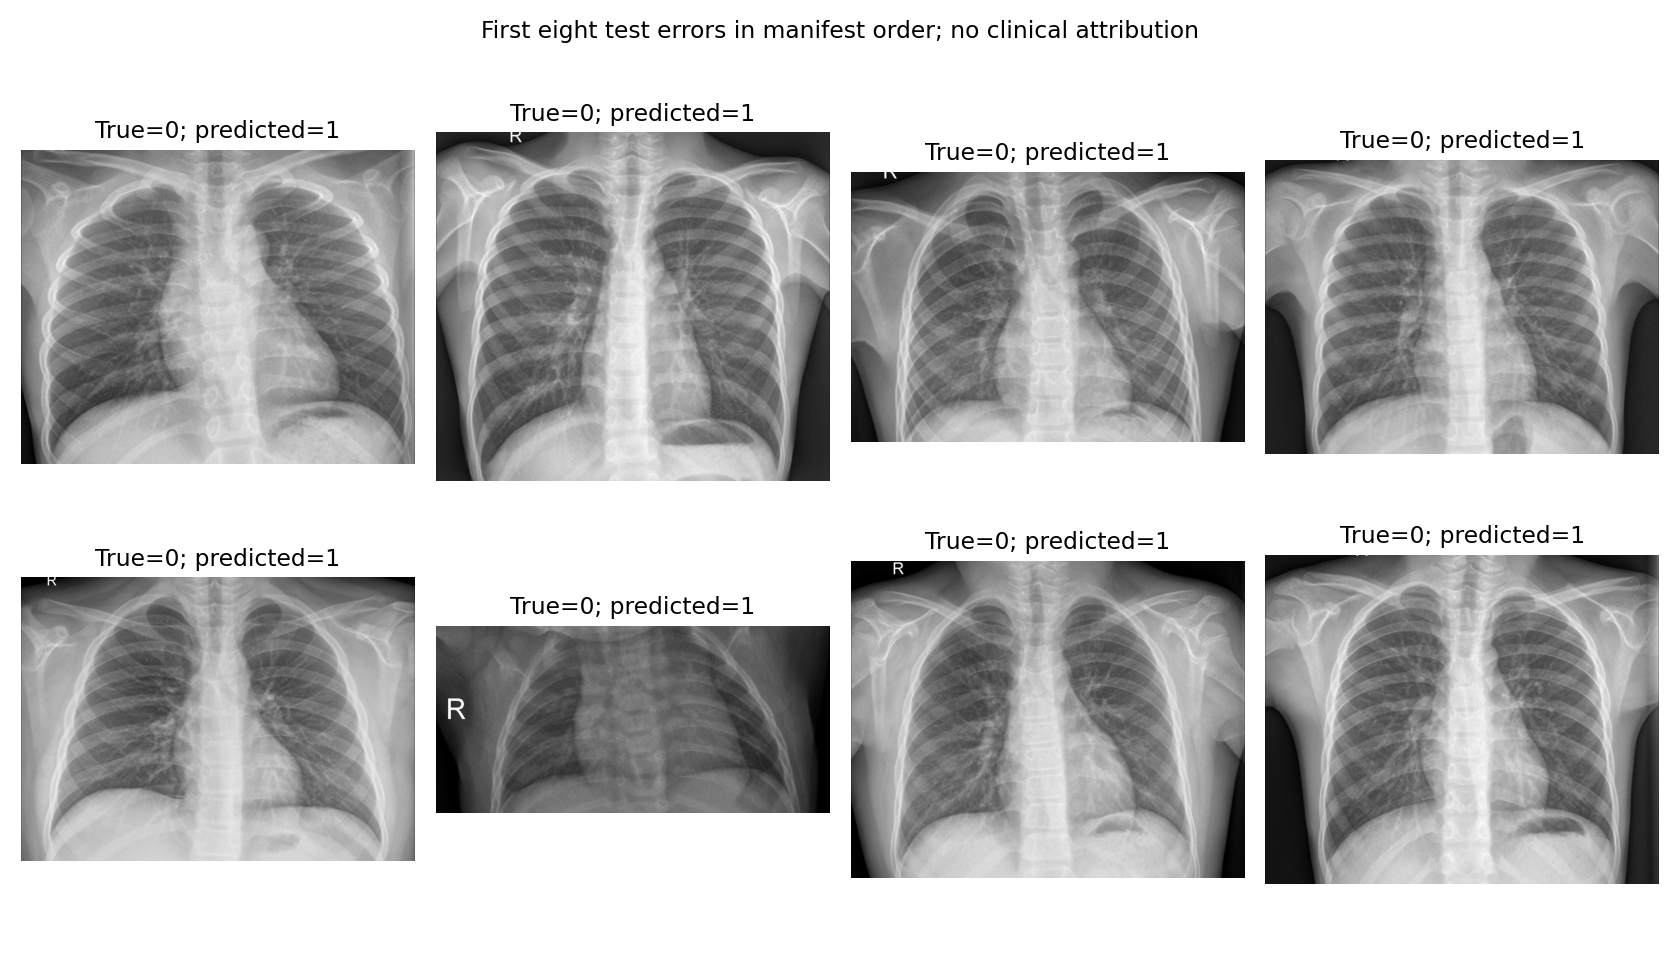

In [7]:
display(pd.read_csv(OUTPUT / 'results/model_comparison_cv.csv'))
display(pd.read_csv(OUTPUT / 'results/feature_scaling_ablation.csv'))
print('Scaling check:', (OUTPUT / 'results/scaling_diagnostics.json').read_text())
display(NotebookImage(filename=str(OUTPUT / 'report/figures/final_evaluation.png')))
predictions = pd.read_csv(OUTPUT / 'results/test_predictions.csv')
errors = predictions[predictions.target != predictions.prediction]
print('Test errors:', len(errors))
fig, axes = plt.subplots(2, 4, figsize=(12, 7))
for ax in axes.ravel(): ax.axis('off')
for ax, row in zip(axes.ravel(), errors.head(8).itertuples()):
    with Image.open(root / row.path) as im: ax.imshow(im.convert('L'), cmap='gray')
    ax.set_title(f'True={row.target}; predicted={row.prediction}')
fig.suptitle('First eight test errors in manifest order; no clinical attribution')
fig.tight_layout()
error_path = OUTPUT / 'report/figures/error_examples.png'
fig.savefig(error_path, dpi=140); plt.close(fig)
display(NotebookImage(filename=str(error_path)))


## 7. Conclusions, limitations and viva preparation

Use the measured outputs above for your conclusions: compare the selected CV mean with the majority baseline; compare full features with intensity-only; assess whether scaling helped the fixed logistic model; contrast CV and held-out test balanced accuracy; discuss false negatives and specificity alongside accuracy.

**Limitations:** filename-derived grouping; internal single-source test; possible near duplicates and annotation errors; pediatric population; no external validation; low-resolution features; padding/markers/acquisition confounding; no calibrated probabilities; selection-biased development summaries; bootstrap intervals conditional on one training run. No claim of clinical readiness or performance parity with published neural networks is justified.

**Be ready to explain:** Why accuracy alone is inadequate; why normalization differs from standardization; why scaling before CV leaks information; why patient grouping matters; how class weights affect the objective; how `C` controls bias/variance; why SVM scores are not probabilities; why a test set cannot select thresholds; why external validation is necessary.

**Saved outputs:** manifest and exclusions, fixed fold assignments, full CV grids, feature/scaling ablations, OOF and test predictions, test metrics and confidence intervals, figures, package versions, fitted pipeline and threshold. Raw images and binary models are git-ignored; regenerate them with this notebook. Review `report/phase1_report.md` for the written evaluation narrative.

In [8]:
# Optional Colab download: results, figures and trained model (no raw images).
import zipfile
archive = OUTPUT / 'phase1_results.zip'
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for folder in ('results', 'report', 'models'):
        for p in (OUTPUT / folder).rglob('*'):
            if p.is_file(): z.write(p, p.relative_to(OUTPUT))
print('Saved:', archive)
# In Colab, uncomment to download:
# from google.colab import files
# files.download(str(archive))


Saved: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML/phase1_results.zip
